In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", device)

Устройство: cpu


#1.1 адаптировать модель к набору данных CIFAR10

In [ ]:
transfor_rgb = transforms.Compose([
    transforms.Resize(28),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

full_train_dataset = torchvision.datasets.CIFAR10(root="./data",
                                                  train=True,
                                                  download=True,
                                                  transform=transfor_rgb)
test_dataset = torchvision.datasets.CIFAR10(root="./data",
                                            train=False,
                                            download=True,
                                            transform=transfor_rgb)

train_dataset, val_dataset = random_split(full_train_dataset, [45000, 5000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Обучающая выборка:", len(train_dataset))
print("Валидационная выборка:", len(val_dataset))
print("Тестовая выборка:", len(test_dataset))

Обучающая выборка: 45000
Валидационная выборка: 5000
Тестовая выборка: 10000


In [ ]:
class NetC(nn.Module):

    def __init__(self, output_dim, input_dim=3):
        super(NetC, self).__init__()
        self.dp_one = nn.Dropout(0.2)
        self.dp_two = nn.Dropout(0.2)

        self.bn_one = nn.BatchNorm2d(input_dim)
        self.conv_one = nn.Conv2d(input_dim, 30, 3)
        self.bn_two = nn.BatchNorm2d(30)
        self.conv_two = nn.Conv2d(30, 60, 3)
        self.bn_three = nn.BatchNorm2d(60)
        self.conv_three = nn.Conv2d(60, 120, 3)
        self.bn_four = nn.BatchNorm2d(120)

        self.fc1 = nn.Linear(120, 200)
        self.fc2 = nn.Linear(200, 60)
        self.out = nn.Linear(60, output_dim)

    def forward(self, x):
        x = self.bn_one(x)
        x = self.conv_one(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        x = self.bn_two(x)
        x = self.conv_two(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        x = self.bn_three(x)
        x = self.conv_three(x)
        x = F.leaky_relu(x, 0.1)
        x = F.max_pool2d(x, 2)

        x = self.bn_four(x)
        x = x.view(x.size(0), -1)

        x = self.dp_one(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dp_two(x)
        x = self.fc2(x)
        x = F.relu(x)

        return self.out(x)

net = NetC(output_dim=10, input_dim=3).to(device)
print(net)

NetC(
  (dp_one): Dropout(p=0.2, inplace=False)
  (dp_two): Dropout(p=0.2, inplace=False)
  (bn_one): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv_one): Conv2d(3, 30, kernel_size=(3, 3), stride=(1, 1))
  (bn_two): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv_two): Conv2d(30, 60, kernel_size=(3, 3), stride=(1, 1))
  (bn_three): BatchNorm2d(60, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv_three): Conv2d(60, 120, kernel_size=(3, 3), stride=(1, 1))
  (bn_four): BatchNorm2d(120, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc1): Linear(in_features=120, out_features=200, bias=True)
  (fc2): Linear(in_features=200, out_features=60, bias=True)
  (out): Linear(in_features=60, out_features=10, bias=True)
)


#1.2 провести обучение - получить результаты

In [ ]:
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

num_epochs = 5

for epoch in range(num_epochs):
    net.train()
    running_loss, running_items, running_right = 0.0, 0, 0

    for i, data in enumerate(train_loader):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(labels)
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum().item()

    net.eval()
    test_running_right, test_running_total = 0, 0

    with torch.no_grad():
        for data in test_loader:
            test_outputs = net(data[0].to(device))
            test_running_total += len(data[1])
            test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum().item()

    print(f'Epoch [{epoch + 1}/{num_epochs}]. '
          f'Loss: {running_loss / running_items:.3f}. '
          f'Train acc: {running_right / running_items:.3f}. '
          f'Test acc: {test_running_right / test_running_total:.3f}')

print('Training is finished!')

Epoch [1/5]. Loss: 1.627. Train acc: 0.402. Test acc: 0.488
Epoch [2/5]. Loss: 1.387. Train acc: 0.509. Test acc: 0.546
Epoch [3/5]. Loss: 1.276. Train acc: 0.553. Test acc: 0.589
Epoch [4/5]. Loss: 1.215. Train acc: 0.580. Test acc: 0.596
Epoch [5/5]. Loss: 1.154. Train acc: 0.604. Test acc: 0.605
Training is finished!


#Вариант 1. MaxPooling или AvgPooling. На одной архитектуре сравните максимальный и средний pooling с одинаковыми размером окна 2×2 и шагом 2 во всех трёх блоках. Обучите обе модели заново. Сравните валидационную accuracy и покажите карты после первого pooling для одного и того же изображения. Объясните, какие особенности откликов сохраняет каждый способ агрегации.

In [ ]:
class NetCAvg(NetC):
    def forward(self, x):
        x = self.bn_one(x)
        x = self.conv_one(x)
        x = F.relu(x)
        x = F.avg_pool2d(x, 2)

        x = self.bn_two(x)
        x = self.conv_two(x)
        x = F.relu(x)
        x = F.avg_pool2d(x, 2)

        x = self.bn_three(x)
        x = self.conv_three(x)
        x = F.leaky_relu(x, 0.1)
        x = F.avg_pool2d(x, 2)

        x = self.bn_four(x)
        x = x.view(x.size(0), -1)

        x = self.dp_one(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dp_two(x)
        x = self.fc2(x)
        x = F.relu(x)

        return self.out(x)

net_max = NetC(output_dim=10, input_dim=3).to(device)
net_avg = NetCAvg(output_dim=10, input_dim=3).to(device)

net_avg.load_state_dict(net_max.state_dict())

<All keys matched successfully>

In [ ]:
for name, model in [('MaxPooling', net_max), ('AvgPooling', net_avg)]:
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(5):
        model.train()

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        model.eval()
        val_right, val_total = 0, 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_total += len(labels)
                val_right += (labels == torch.max(outputs, 1)[1]).sum().item()

        print(f'{name}, epoch [{epoch + 1}/5], Val acc: {val_right / val_total:.3f}')

MaxPooling, epoch [1/5], Val acc: 0.486
MaxPooling, epoch [2/5], Val acc: 0.535
MaxPooling, epoch [3/5], Val acc: 0.553
MaxPooling, epoch [4/5], Val acc: 0.538
MaxPooling, epoch [5/5], Val acc: 0.581
AvgPooling, epoch [1/5], Val acc: 0.463
AvgPooling, epoch [2/5], Val acc: 0.520
AvgPooling, epoch [3/5], Val acc: 0.535
AvgPooling, epoch [4/5], Val acc: 0.564
AvgPooling, epoch [5/5], Val acc: 0.597


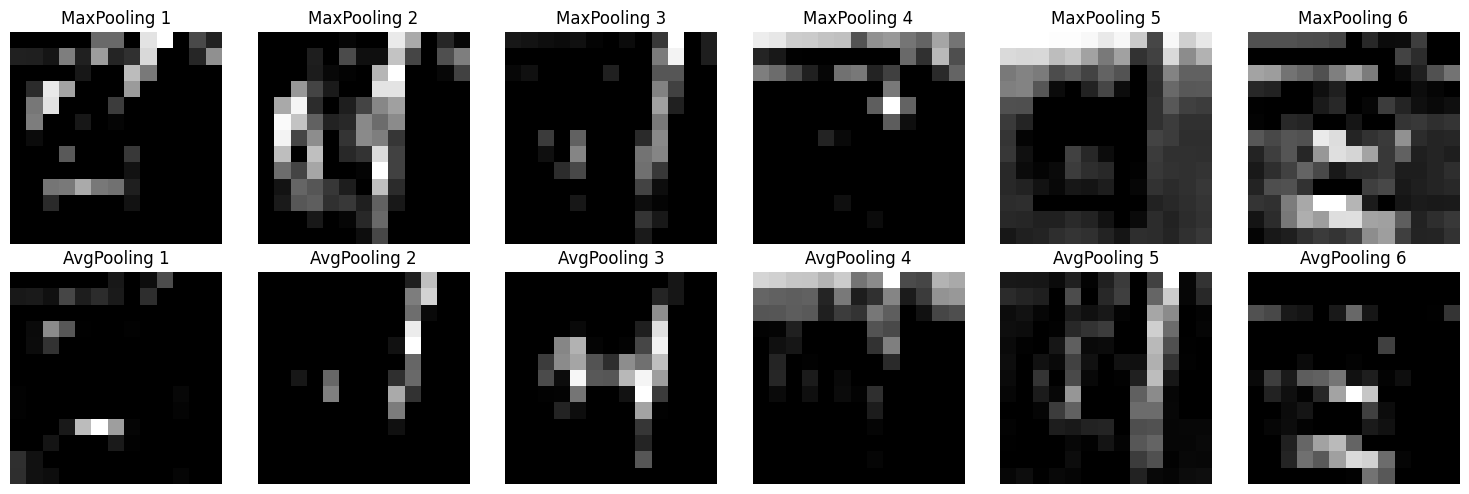

In [ ]:
image = val_dataset[0][0].unsqueeze(0).to(device)

with torch.no_grad():
    x_max = net_max.bn_one(image)
    x_max = net_max.conv_one(x_max)
    x_max = F.relu(x_max)
    x_max = F.max_pool2d(x_max, 2)

    x_avg = net_avg.bn_one(image)
    x_avg = net_avg.conv_one(x_avg)
    x_avg = F.relu(x_avg)
    x_avg = F.avg_pool2d(x_avg, 2)

plt.figure(figsize=(15, 5))

for i in range(6):
    plt.subplot(2, 6, i + 1)
    plt.imshow(x_max[0, i].cpu().numpy(), cmap='gray')
    plt.title(f'MaxPooling {i + 1}')
    plt.axis('off')

    plt.subplot(2, 6, i + 7)
    plt.imshow(x_avg[0, i].cpu().numpy(), cmap='gray')
    plt.title(f'AvgPooling {i + 1}')
    plt.axis('off')

plt.tight_layout()
plt.show()

MaxPooling сохраняет наиболее сильные признаки изображения, делая их более заметными

AvgPooling усредняет значения, поэтому изображение получается более сглаженным.

Оба способа показали близкие результаты, но AvgPooling оказался немного точнее

#2.1 добавить резидуальный обход
#2.2 сделать более глубокую сеть

In [ ]:
class NetCDeep(nn.Module):

    def __init__(self, output_dim, input_dim=3):
        super(NetCDeep, self).__init__()
        self.dp_one = nn.Dropout(0.2)
        self.dp_two = nn.Dropout(0.2)

        self.bn_one1 = nn.BatchNorm2d(input_dim)
        self.bn_one2 = nn.BatchNorm2d(30)
        self.conv_one1 = nn.Conv2d(input_dim, 30, 3, padding=1)
        self.conv_one2 = nn.Conv2d(30, 30, 3)

        self.bn_two = nn.BatchNorm2d(30)
        self.conv_two1 = nn.Conv2d(30, 30, 3, padding=1)
        self.conv_two2 = nn.Conv2d(30, 30, 3, padding=1)
        self.conv_two3 = nn.Conv2d(30, 60, 3)

        self.bn_three = nn.BatchNorm2d(60)
        self.conv_three = nn.Conv2d(60, 120, 3)
        self.bn_four = nn.BatchNorm2d(120)

        self.fc1 = nn.Linear(120, 200)
        self.fc2 = nn.Linear(200, 60)
        self.out = nn.Linear(60, output_dim)

    def forward(self, x):
        x = self.bn_one1(x)
        x = self.conv_one1(x)
        x = F.relu(x)
        x = self.conv_one2(x)
        x = F.relu(x)
        x = self.bn_one2(x)
        x = F.max_pool2d(x, 2)

        x = self.bn_two(x)
        x3 = x
        x = self.conv_two1(x)
        x = F.relu(x)
        x = self.conv_two2(x)
        x = F.relu(x)
        x = x + x3
        x = self.conv_two3(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)

        x = self.bn_three(x)
        x = self.conv_three(x)
        x = F.leaky_relu(x, 0.1)
        x = F.max_pool2d(x, 2)

        x = self.bn_four(x)
        x = x.view(x.size(0), -1)

        x = self.dp_one(x)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dp_two(x)
        x = self.fc2(x)
        x = F.relu(x)

        return self.out(x)

net = NetCDeep(output_dim=10, input_dim=3).to(device)
print(net)

NetCDeep(
  (dp_one): Dropout(p=0.2, inplace=False)
  (dp_two): Dropout(p=0.2, inplace=False)
  (bn_one1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (bn_one2): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv_one1): Conv2d(3, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_one2): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1))
  (bn_two): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv_two1): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_two2): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_two3): Conv2d(30, 60, kernel_size=(3, 3), stride=(1, 1))
  (bn_three): BatchNorm2d(60, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv_three): Conv2d(60, 120, kernel_size=(3, 3), stride=(1, 1))
  (bn_four): BatchNorm2d(120, eps=1e-05, momentum=0.

In [ ]:
optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

num_epochs = 5

for epoch in range(num_epochs):
    net.train()
    running_loss, running_items, running_right = 0.0, 0, 0

    for i, data in enumerate(train_loader):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(labels)
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum().item()

    net.eval()
    test_running_right, test_running_total = 0, 0

    with torch.no_grad():
        for data in test_loader:
            test_outputs = net(data[0].to(device))
            test_running_total += len(data[1])
            test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum().item()

    print(f'Epoch [{epoch + 1}/{num_epochs}]. '
          f'Loss: {running_loss / running_items:.3f}. '
          f'Train acc: {running_right / running_items:.3f}. '
          f'Test acc: {test_running_right / test_running_total:.3f}')

print('Training is finished!')

Epoch [1/5]. Loss: 1.675. Train acc: 0.380. Test acc: 0.470
Epoch [2/5]. Loss: 1.350. Train acc: 0.517. Test acc: 0.555
Epoch [3/5]. Loss: 1.200. Train acc: 0.581. Test acc: 0.591
Epoch [4/5]. Loss: 1.102. Train acc: 0.621. Test acc: 0.597
Epoch [5/5]. Loss: 1.029. Train acc: 0.647. Test acc: 0.600
Training is finished!


#3.1. Сделать аугментации данных

In [ ]:
transfor_rgb_flip25 = transforms.Compose([
    transforms.Resize(28),
    transforms.RandomHorizontalFlip(p=0.25),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transfor_rgb_flip50 = transforms.Compose([
    transforms.Resize(28),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = full_train_dataset
train_dataset_flip25 = torchvision.datasets.CIFAR10(root="./data",
                                                    train=True,
                                                    download=True,
                                                    transform=transfor_rgb_flip25)
train_dataset_flip50 = torchvision.datasets.CIFAR10(root="./data",
                                                    train=True,
                                                    download=True,
                                                    transform=transfor_rgb_flip50)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
train_loader_flip25 = DataLoader(train_dataset_flip25, batch_size=64, shuffle=True)
train_loader_flip50 = DataLoader(train_dataset_flip50, batch_size=64, shuffle=True)

#3.2 провести обучение на аугментированных данных

In [ ]:
net = NetC(output_dim=10, input_dim=3).to(device)

optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

num_epochs = 5

for epoch in range(num_epochs):
    net.train()
    running_loss, running_items, running_right = 0.0, 0, 0

    for i, data in enumerate(train_loader_flip50):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(labels)
        running_items += len(labels)
        running_right += (labels == torch.max(outputs, 1)[1]).sum().item()

    net.eval()
    test_running_right, test_running_total = 0, 0

    with torch.no_grad():
        for data in test_loader:
            test_outputs = net(data[0].to(device))
            test_running_total += len(data[1])
            test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum().item()

    print(f'Epoch [{epoch + 1}/{num_epochs}]. '
          f'Loss: {running_loss / running_items:.3f}. '
          f'Train acc: {running_right / running_items:.3f}. '
          f'Test acc: {test_running_right / test_running_total:.3f}')

print('Training is finished!')

Epoch [1/5]. Loss: 1.615. Train acc: 0.407. Test acc: 0.490
Epoch [2/5]. Loss: 1.360. Train acc: 0.519. Test acc: 0.561
Epoch [3/5]. Loss: 1.259. Train acc: 0.566. Test acc: 0.598
Epoch [4/5]. Loss: 1.190. Train acc: 0.589. Test acc: 0.602
Epoch [5/5]. Loss: 1.139. Train acc: 0.612. Test acc: 0.619
Training is finished!


#Вариант 1. Горизонтальное отражение. Сравните отсутствие отражения и RandomHorizontalFlip с вероятностями 0.25 и 0.5. Объясните, почему допустимость преобразования зависит от задачи и можно ли автоматически переносить такой выбор с CIFAR10 на распознавание цифр.

In [ ]:
acc_flip50 = test_running_right / test_running_total
results = {}

for name, loader in [('p=0', train_loader), ('p=0.25', train_loader_flip25)]:
    net = NetC(output_dim=10, input_dim=3).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)

    for epoch in range(5):
        net.train()
        running_loss, running_items, running_right = 0.0, 0, 0

        for i, data in enumerate(loader):
            inputs, labels = data[0].to(device), data[1].to(device)

            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(labels)
            running_items += len(labels)
            running_right += (labels == torch.max(outputs, 1)[1]).sum().item()

        net.eval()
        test_running_right, test_running_total = 0, 0

        with torch.no_grad():
            for data in test_loader:
                test_outputs = net(data[0].to(device))
                test_running_total += len(data[1])
                test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum().item()

        print(f'{name}, Epoch [{epoch + 1}/5]. '
              f'Loss: {running_loss / running_items:.3f}. '
              f'Train acc: {running_right / running_items:.3f}. '
              f'Test acc: {test_running_right / test_running_total:.3f}')

    results[name] = test_running_right / test_running_total
    print()

results['p=0.5'] = acc_flip50

print('Итоговые результаты:')
for name, acc in results.items():
    print(f'{name}: Test acc = {acc:.3f}')

p=0, Epoch [1/5]. Loss: 1.637. Train acc: 0.399. Test acc: 0.493
p=0, Epoch [2/5]. Loss: 1.380. Train acc: 0.513. Test acc: 0.560
p=0, Epoch [3/5]. Loss: 1.267. Train acc: 0.558. Test acc: 0.553
p=0, Epoch [4/5]. Loss: 1.202. Train acc: 0.583. Test acc: 0.585
p=0, Epoch [5/5]. Loss: 1.149. Train acc: 0.606. Test acc: 0.605

p=0.25, Epoch [1/5]. Loss: 1.606. Train acc: 0.416. Test acc: 0.499
p=0.25, Epoch [2/5]. Loss: 1.353. Train acc: 0.526. Test acc: 0.557
p=0.25, Epoch [3/5]. Loss: 1.251. Train acc: 0.567. Test acc: 0.594
p=0.25, Epoch [4/5]. Loss: 1.197. Train acc: 0.589. Test acc: 0.614
p=0.25, Epoch [5/5]. Loss: 1.136. Train acc: 0.612. Test acc: 0.624

Итоговые результаты:
p=0: Test acc = 0.605
p=0.25: Test acc = 0.624
p=0.5: Test acc = 0.619


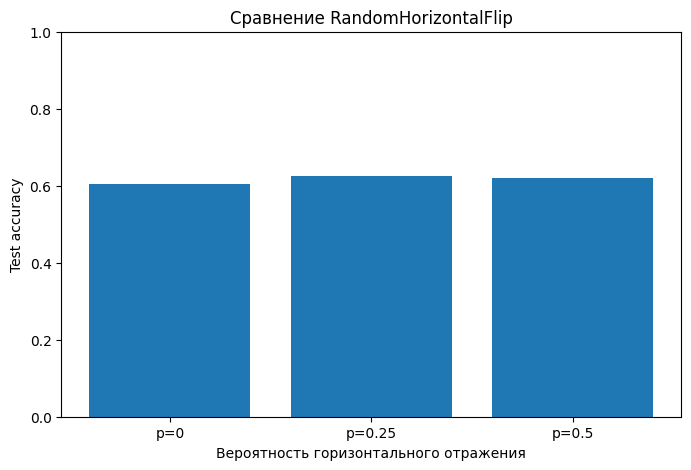

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(results.keys(), results.values())
plt.xlabel('Вероятность горизонтального отражения')
plt.ylabel('Test accuracy')
plt.title('Сравнение RandomHorizontalFlip')
plt.ylim(0, 1)
plt.show()

Преобразование должно сохранять исходный класс объекта, поэтому допустимость аугментации зависит от задачи. В CIFAR10 горизонтальное отражение обычно не меняет класс изображения. При распознавании цифр оно может изменить их форму и сделать изображение некорректным. Автоматически переносить это преобразование на распознавание цифр нельзя

Оба варианта аугментации улучшили результат в сравнении с обучением без аугментаций

#4.1 обучить нейронный сверточный классификатор (3 сверточных слоя с ядром kxk (relu), MaxPooling((2,2)), полносвязный слой 100 нейронов (relu), выходной слой softMax - 10 нейронов) на fasion-mnist и посмотреть как будет изменяться результат обработки для ядра 3х3, 5х5 с визуализацией выходов каждого слоя (для одного примера).

In [ ]:
transfor_gray = transforms.Compose([
    transforms.ToTensor()
])

train_dataset_fashion = torchvision.datasets.FashionMNIST(root="./data",
                                                          train=True,
                                                          download=True,
                                                          transform=transfor_gray)
test_dataset_fashion = torchvision.datasets.FashionMNIST(root="./data",
                                                         train=False,
                                                         download=True,
                                                         transform=transfor_gray)

train_loader_fashion = DataLoader(train_dataset_fashion, batch_size=64, shuffle=True)
test_loader_fashion = DataLoader(test_dataset_fashion, batch_size=128, shuffle=False)

print("Обучающая выборка:", len(train_dataset_fashion))
print("Тестовая выборка:", len(test_dataset_fashion))


Обучающая выборка: 60000
Тестовая выборка: 10000


In [ ]:
class NetFashion(nn.Module):
    def __init__(self, kernel_size):
        super(NetFashion, self).__init__()

        self.conv_one = nn.Conv2d(1, 30, kernel_size, padding=kernel_size // 2)
        self.conv_two = nn.Conv2d(30, 60, kernel_size, padding=kernel_size // 2)
        self.conv_three = nn.Conv2d(60, 120, kernel_size, padding=kernel_size // 2)

        self.fc1 = nn.Linear(120 * 3 * 3, 100)
        self.out = nn.Linear(100, 10)

    def forward(self, x):
        x1 = F.relu(self.conv_one(x))
        x2 = F.max_pool2d(x1, 2)

        x3 = F.relu(self.conv_two(x2))
        x4 = F.max_pool2d(x3, 2)

        x5 = F.relu(self.conv_three(x4))
        x6 = F.max_pool2d(x5, 2)

        x7 = F.relu(self.fc1(x6.view(x6.size(0), -1)))
        outputs = self.out(x7)

        return outputs, x1, x2, x3, x4, x5, x6, x7

In [ ]:
fashion_models = {}
fashion_results = {}
criterion = nn.CrossEntropyLoss()

num_epochs = 5

for kernel_size in [3, 5]:
    net = NetFashion(kernel_size).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)

    print(f'Обучение модели с ядром {kernel_size}x{kernel_size}')

    for epoch in range(num_epochs):
        net.train()
        running_loss, running_items, running_right = 0.0, 0, 0

        for i, data in enumerate(train_loader_fashion):
            inputs, labels = data[0].to(device), data[1].to(device)

            optimizer.zero_grad()
            outputs, *_ = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(labels)
            running_items += len(labels)
            running_right += (labels == torch.max(outputs, 1)[1]).sum().item()

        net.eval()
        test_running_right, test_running_total = 0, 0

        with torch.no_grad():
            for data in test_loader_fashion:
                test_outputs, *_ = net(data[0].to(device))
                test_running_total += len(data[1])
                test_running_right += (data[1].to(device) == torch.max(test_outputs, 1)[1]).sum().item()

        print(f'Epoch [{epoch + 1}/{num_epochs}]. '
              f'Loss: {running_loss / running_items:.3f}. '
              f'Train acc: {running_right / running_items:.3f}. '
              f'Test acc: {test_running_right / test_running_total:.3f}')

    fashion_models[kernel_size] = net
    fashion_results[kernel_size] = test_running_right / test_running_total
    print()

print('Итоговые результаты:')
for kernel_size, acc in fashion_results.items():
    print(f'Ядро {kernel_size}x{kernel_size}: Test acc = {acc:.3f}')

Обучение модели с ядром 3x3
Epoch [1/5]. Loss: 0.542. Train acc: 0.796. Test acc: 0.842
Epoch [2/5]. Loss: 0.372. Train acc: 0.861. Test acc: 0.855
Epoch [3/5]. Loss: 0.346. Train acc: 0.871. Test acc: 0.868
Epoch [4/5]. Loss: 0.336. Train acc: 0.874. Test acc: 0.856
Epoch [5/5]. Loss: 0.320. Train acc: 0.880. Test acc: 0.874

Обучение модели с ядром 5x5
Epoch [1/5]. Loss: 0.484. Train acc: 0.821. Test acc: 0.857
Epoch [2/5]. Loss: 0.349. Train acc: 0.871. Test acc: 0.856
Epoch [3/5]. Loss: 0.328. Train acc: 0.880. Test acc: 0.871
Epoch [4/5]. Loss: 0.319. Train acc: 0.882. Test acc: 0.875
Epoch [5/5]. Loss: 0.318. Train acc: 0.885. Test acc: 0.861

Итоговые результаты:
Ядро 3x3: Test acc = 0.874
Ядро 5x5: Test acc = 0.861


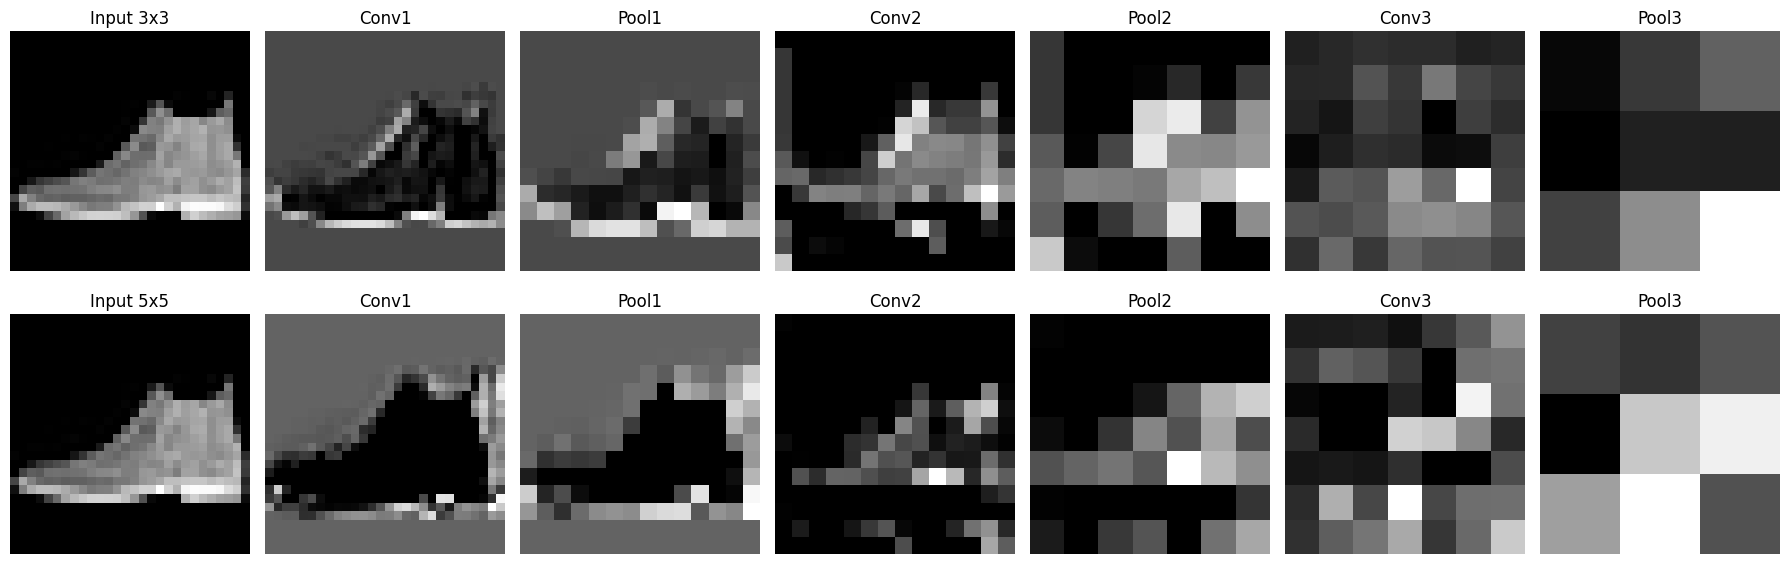

In [36]:
image, label = test_dataset_fashion[0]
image = image.unsqueeze(0).to(device)

fig, ax = plt.subplots(2, 7, figsize=(18, 6))
titles = ['Conv1', 'Pool1', 'Conv2', 'Pool2', 'Conv3', 'Pool3']

for row, kernel_size in enumerate([3, 5]):
    net = fashion_models[kernel_size]
    net.eval()

    with torch.no_grad():
        outputs, x1, x2, x3, x4, x5, x6, x7 = net(image)

    ax[row, 0].imshow(image[0, 0].cpu().numpy(), cmap='gray')
    ax[row, 0].set_title(f'Input {kernel_size}x{kernel_size}')
    ax[row, 0].axis('off')

    for col, x in enumerate([x1, x2, x3, x4, x5, x6]):
        im = x[0].max(dim=0).values.cpu().numpy()
        ax[row, col + 1].imshow(im, cmap='gray')
        ax[row, col + 1].set_title(titles[col])
        ax[row, col + 1].axis('off')

plt.tight_layout()
plt.show()

#4.2 Оценить размеры выходов в режиме padding=1, 2. Предложить постановку задачи, где слой усреднения может работать лучше , чем слой максимизации

In [37]:
for k in [3, 5]:
    for p in [1, 2]:
        h = 28
        print(f'\nЯдро {k}x{k}, padding={p}')

        for i, channels in enumerate([30, 60, 120], 1):
            h = h + 2 * p - k + 1
            print(f'Conv{i}: {channels}x{h}x{h}')
            h = h // 2
            print(f'Pool{i}: {channels}x{h}x{h}')

        print(f'Входных значений для FC: {120 * h * h}')


Ядро 3x3, padding=1
Conv1: 30x28x28
Pool1: 30x14x14
Conv2: 60x14x14
Pool2: 60x7x7
Conv3: 120x7x7
Pool3: 120x3x3
Входных значений для FC: 1080

Ядро 3x3, padding=2
Conv1: 30x30x30
Pool1: 30x15x15
Conv2: 60x17x17
Pool2: 60x8x8
Conv3: 120x10x10
Pool3: 120x5x5
Входных значений для FC: 3000

Ядро 5x5, padding=1
Conv1: 30x26x26
Pool1: 30x13x13
Conv2: 60x11x11
Pool2: 60x5x5
Conv3: 120x3x3
Pool3: 120x1x1
Входных значений для FC: 120

Ядро 5x5, padding=2
Conv1: 30x28x28
Pool1: 30x14x14
Conv2: 60x14x14
Pool2: 60x7x7
Conv3: 120x7x7
Pool3: 120x3x3
Входных значений для FC: 1080


AvgPooling может работать лучше MaxPooling в задаче классификации изображений по средней плотности заполнения области. AvgPooling учитывает все значения в окне и сохраняет информацию об их среднем уровне, а MaxPooling выбирает только наибольшее значение и сильно реагирует на отдельные яркие пиксели

#Вариант 1. Ошибки по классам. Постройте матрицу ошибок и найдите две наиболее частые направленные ошибки «истинный класс → предсказанный класс» вне диагонали. Для каждой укажите число ошибок и долю среди объектов истинного класса. Покажите до трёх ошибочно классифицированных изображений для каждой пары, подпишите истинный и предсказанный классы. Объясните возможные причины путаницы и почему общей accuracy недостаточно для такого анализа.

In [ ]:
from sklearn.metrics import confusion_matrix

best_kernel = max(fashion_results, key=fashion_results.get)
best_model = fashion_models[best_kernel]
best_model.eval()

y_true, y_pred = [], []
wrong_examples = {}

with torch.no_grad():
    for inputs, labels in test_loader_fashion:
        outputs = best_model(inputs.to(device))[0]
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

        for image, true_label, predicted_label in zip(inputs, labels, predictions):
            if true_label.item() != predicted_label.item():
                key = (true_label.item(), predicted_label.item())
                wrong_examples.setdefault(key, [])

                if len(wrong_examples[key]) < 3:
                    wrong_examples[key].append(image[0].numpy())

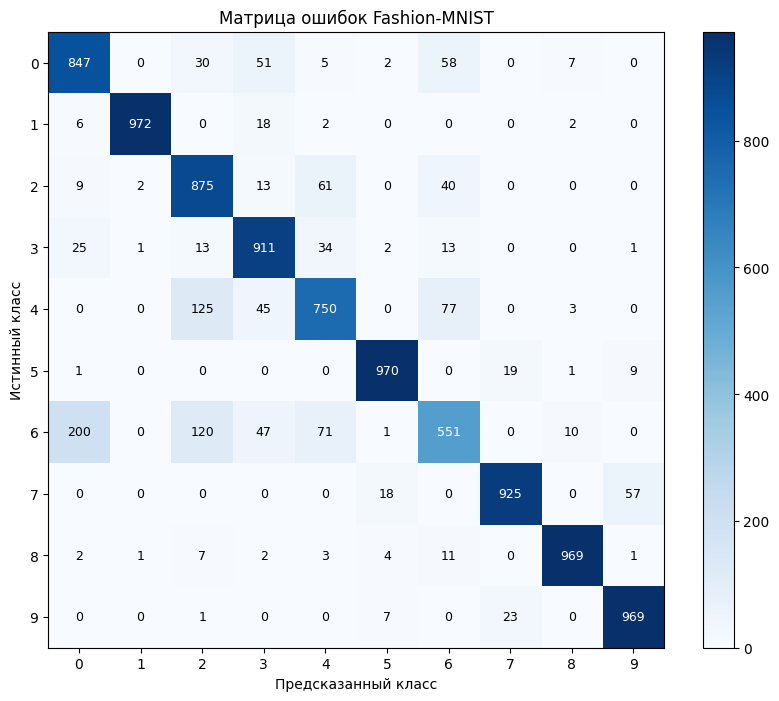

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap='Blues')
plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=9)

plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок Fashion-MNIST')
plt.show()

In [ ]:
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

top_pairs = sorted(
    [(i, j, cm_off[i, j]) for i in range(10) for j in range(10) if i != j],
    key=lambda v: v[2],
    reverse=True
)[:2]

for true_label, predicted_label, count in top_pairs:
    share = count / cm[true_label].sum()

    print(
        f'{train_dataset_fashion.classes[true_label]} → '
        f'{train_dataset_fashion.classes[predicted_label]}: '
        f'{count} ошибок; доля среди истинного класса {share:.2%}'
    )

Shirt → T-shirt/top: 200 ошибок; доля среди истинного класса 20.00%
Coat → Pullover: 125 ошибок; доля среди истинного класса 12.50%


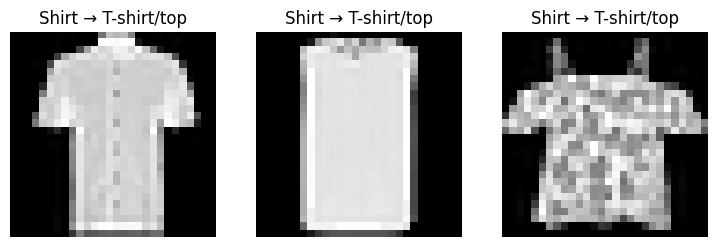

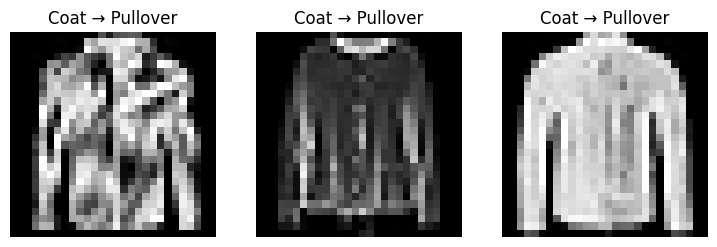

In [ ]:
for true_label, predicted_label, count in top_pairs:
    images = wrong_examples.get((true_label, predicted_label), [])

    fig, axes = plt.subplots(1, max(1, len(images)), figsize=(3 * max(1, len(images)), 3))
    axes = np.atleast_1d(axes)

    for ax, picture in zip(axes, images):
        ax.imshow(picture, cmap='gray')
        ax.set_title(
            f'{train_dataset_fashion.classes[true_label]} → '
            f'{train_dataset_fashion.classes[predicted_label]}'
        )
        ax.axis('off')

    plt.show()

Если изображения имеют похожие силуэты, то модель может путать классы из-за схожести формы одежды и низкого разрешения изображений

Общей accuracy недостаточно, т.к. она показывает только долю правильных предсказаний. С ее помощью нельзя определить, какие именно классы модель путает и насколько часто возникают конкретные ошибки